# 注意力评分函数（Attention Scoring Functions）

在上一节 Nadaraya-Watson 核回归中，我们通过 Query（Q）和 Key（K）之间的距离计算注意力权重，再对 Value（V）加权求和。但在实际深度学习任务中，Q、K、V 通常是高维向量，因此需要更灵活的方式衡量 Q 和 K 的相关性。

**注意力评分函数（Attention Scoring Function）** 用于计算 Q 与 K 的匹配分数，经过 Softmax 归一化得到注意力权重，最后对 V 加权求和，得到注意力输出。

本节主要学习三部分：**掩蔽 Softmax（Masked Softmax）**、**加性注意力（Additive Attention）和缩放点积注意力（Scaled Dot-Product Attention）**。其中，缩放点积注意力是后续 Transformer 的核心基础。


In [1]:
import math
import torch
from torch import nn
from d2l import torch as d2l

## 10.3.1 掩蔽 Softmax（Masked Softmax）

### 工作原理

普通 Softmax 会给所有 Key 分配注意力权重，但实际任务中可能存在 `<pad>` 等无效位置，需要通过 Mask 排除。

例如，句子 `[我, 喜欢]` 为了统一长度，被填充为 `[我, 喜欢, <pad>, <pad>]`。后两个 Token 不包含有效信息，不应该参与注意力计算。

**核心机制：先将无效位置的注意力分数替换为极大的负数，再执行 Softmax，使其权重接近 0，有效位置的权重重新归一化。**

假设某个 Query 对上述四个 Key 的原始注意力分数为：

$$
S=[2,1,5,0],\quad valid\_len=2
$$

Mask 后：

$$
S'=[2,1,-10^6,-10^6]
$$

Softmax 后：

$$
\boxed{\alpha=[0.7311,0.2689,0,0]}
$$

最终，注意力只分配给“我”和“喜欢”，两个 `<pad>` 的注意力权重为 0。

`valid_lens` 表示每个样本或每个 Query 有多少个有效 Key，可以是一维（每个样本一个有效长度）或二维（每个 Query 一个有效长度）。

In [2]:

def masked_softmax(X, valid_lens):
    """通过在最后一个轴上掩蔽元素来执行softmax操作"""
    # X: 3D张量，valid_lens: 1D或2D张量
    if valid_lens is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape
        if valid_lens.dim() == 1:
            valid_lens = torch.repeat_interleave(valid_lens, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)
        X = d2l.sequence_mask(X.reshape(-1, shape[-1]), valid_lens, value=-1e6)
        return nn.functional.softmax(X.reshape(shape), dim=-1)


In [4]:
# 2 个批次，每个批次有 2 个样本，每个样本有 4 个 Token，两个批次的有效长度分别是 2 和 3
masked_softmax(torch.rand(2, 2, 4), torch.tensor([2, 3]))

tensor([[[0.4797, 0.5203, 0.0000, 0.0000],
         [0.6704, 0.3296, 0.0000, 0.0000]],

        [[0.4024, 0.2956, 0.3021, 0.0000],
         [0.3204, 0.3361, 0.3435, 0.0000]]])

In [5]:
# 可以使用二维张量，为矩阵样本中的每一行指定有效长度
masked_softmax(torch.rand(2, 2, 4), torch.tensor([[1, 3], [2, 4]]))

tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3595, 0.3500, 0.2905, 0.0000]],

        [[0.6127, 0.3873, 0.0000, 0.0000],
         [0.1867, 0.3864, 0.1936, 0.2334]]])

## 10.3.2 加性注意力（Additive Attention）

### 工作原理

在 Nadaraya-Watson 核回归中，我们通过 Q 和 K 的距离计算注意力分数。但在实际任务中，Q、K 往往是高维向量，甚至维度不同，无法直接进行逐元素加法或点积。

**核心机制：通过可学习的线性变换，将 Q 和 K 映射到相同维度，再通过非线性激活函数和线性变换，计算两者的匹配分数。**

加性注意力的评分公式：

$$
\boxed{a(q,k)=w_v^\top\tanh(W_qq+W_kk)}
$$

其中：

- $W_q$：将 Query 映射到隐藏特征空间。
- $W_k$：将 Key 映射到相同的隐藏特征空间。
- $\tanh$：引入非线性，使模型能够学习更复杂的匹配关系。公式：
  $$\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}$$
- $w_v$：将隐藏特征映射为一个标量注意力分数，注意它不是 QKV 中的 Value。
  

### 计算过程

假设原始 Q 为二维，K 为三维，通过 $W_q$ 和 $W_k$ 将它们统一映射到二维空间：

$$
q'=W_qq=[1,0],\quad k_1'=[1,0],\quad k_2'=[0,1]
$$

假设评分参数：

$$
w_v=[1,-1]
$$

**第一步：分别计算 Q 与两个 Key 的注意力分数。**

$$
s_1=w_v^\top\tanh(q'+k_1')=[1,-1]\cdot[0.964,0]=0.964
$$

$$
s_2=w_v^\top\tanh(q'+k_2')=[1,-1]\cdot[0.762,0.762]=0
$$

**第二步：Softmax 归一化，得到注意力权重。**

$$
\alpha=\operatorname{softmax}([0.964,0])\approx[0.724,0.276]
$$

**第三步：对 Value 加权求和。**

假设 $V=[10,20]$：

$$
\boxed{\hat y=0.724\times10+0.276\times20=12.76}
$$

### 核心总结

加性注意力通过三组可学习参数 $W_q,W_k,w_v$ 学习 Q-K 的匹配规则，所有训练样本共享这些参数，通过任务损失反向传播更新。

**与核回归的主要区别在于注意力评分方式：核回归基于距离计算评分，加性注意力通过可学习的非线性评分网络计算评分；Softmax 归一化和 Value 加权求和的机制不变。**

In [9]:
class AdditiveAttention(nn.Module):
    def __init__(self, key_size, query_size, num_hiddens, dropout, **kwargs):
        super(AdditiveAttention, self).__init__(**kwargs)
        self.W_k = nn.Linear(key_size, num_hiddens, bias=False)
        self.W_q = nn.Linear(query_size, num_hiddens, bias=False)
        self.w_v = nn.Linear(num_hiddens, 1, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, queries, keys, values, valid_lens):
        queries, keys = self.W_q(queries), self.W_k(keys)
        # 在维度扩展后，
        # queries的形状：(batch_size，查询的个数，1，num_hidden)
        # key的形状：(batch_size，1，“键－值”对的个数，num_hiddens)
        # 使用广播方式进行求和
        features = queries.unsqueeze(2) + keys.unsqueeze(1)
        features = torch.tanh(features)
        # self.w_v仅有一个输出，因此从形状中移除最后那个维度。
        # scores的形状：(batch_size，查询的个数，“键-值”对的个数)
        scores = self.w_v(features).squeeze(-1)
        self.attention_weights = masked_softmax(scores, valid_lens)
        # values的形状：(batch_size，“键－值”对的个数，值的维度)
        return torch.bmm(self.dropout(self.attention_weights), values)

### 1. 整体流程

加性注意力通过三个可学习线性层 $W_q$、$W_k$、$w_v$ 计算注意力分数，再通过 Masked Softmax 和 Value 加权求和得到输出。

$$
\boxed{a(q,k)=w_v^\top\tanh(W_qq+W_kk)}
$$

- $W_q$、$W_k$：将 Q、K 映射到相同的隐藏维度 `num_hiddens`。
- $w_v$：将隐藏特征映射成一个标量注意力分数。
- `Dropout`：训练时随机丢弃部分注意力权重，降低过拟合风险。
- `torch.bmm`：将注意力权重与 Value 批量矩阵相乘，得到最终输出。

### 2. 重点：unsqueeze 与广播机制

**核心目的：让每个 Query 与所有 Key 两两配对，而不是只让相同位置的 Q、K 相加。**

假设只有一个 Batch，包含 2 个 Query、3 个 Key，隐藏维度为 2。

经过 $W_q$、$W_k$ 线性变换后：

$$
Q'=\begin{bmatrix}1&0\\0&1\end{bmatrix},\quad K'=\begin{bmatrix}1&1\\2&0\\0&2\end{bmatrix}
$$

对应形状：

$$
Q':(1,2,2),\quad K':(1,3,2)
$$

直接相加无法广播，因为 Query 数量 2 和 Key 数量 3 不兼容。

因此执行 `queries.unsqueeze(2) + keys.unsqueeze(1)`，增加独立的 Query 和 Key 维度：

$$
Q':(1,2,2)\rightarrow(1,2,1,2)
$$

$$
K':(1,3,2)\rightarrow(1,1,3,2)
$$

广播相加：

$$
\boxed{(1,2,1,2)+(1,1,3,2)\rightarrow(1,2,3,2)}
$$

具体计算：

第一个 Query $q_1=[1,0]$，分别与三个 Key 相加：

$$
\begin{aligned}
q_1+k_1&=[1,0]+[1,1]=[2,1]\\
q_1+k_2&=[1,0]+[2,0]=[3,0]\\
q_1+k_3&=[1,0]+[0,2]=[1,2]
\end{aligned}
$$

第二个 Query $q_2=[0,1]$，同样与三个 Key 相加：

$$
\begin{aligned}
q_2+k_1&=[0,1]+[1,1]=[1,2]\\
q_2+k_2&=[0,1]+[2,0]=[2,1]\\
q_2+k_3&=[0,1]+[0,2]=[0,3]
\end{aligned}
$$

最终 `features` 为：

$$
\boxed{
features=
\begin{bmatrix}
[2,1]&[3,0]&[1,2]\\
[1,2]&[2,1]&[0,3]
\end{bmatrix}
}
$$

这里省略了 Batch 维度，实际形状为 `(1,2,3,2)`。

**注意：`unsqueeze` 不只是为了满足广播条件，更重要的是通过独立的 Query 和 Key 维度，生成全部 Q-K 组合。**

### 3. 计算注意力分数

对 `features` 中的每个元素执行 tanh，形状不变：

$$
(1,2,3,2)\rightarrow(1,2,3,2)
$$

假设 $w_v=[1,-1]$，则每个二维特征通过点积变成一个标量分数。

例如：

$$
s_{11}=[1,-1]\cdot\tanh([2,1])=0.964-0.762=0.202
$$

对全部 Q-K 组合计算后：

$$
S\approx\begin{bmatrix}
0.202&0.995&-0.202\\
-0.202&0.202&-0.995
\end{bmatrix}
$$

`self.w_v(features)` 将最后一维从 2 变为 1，随后 `squeeze(-1)` 删除该维度：

$$
(1,2,3,2)\rightarrow(1,2,3,1)\rightarrow\boxed{(1,2,3)}
$$



In [10]:
queries, keys = torch.normal(0, 1, (2, 1, 20)), torch.ones((2, 10, 2))
# values的小批量，两个值矩阵是相同的
values = torch.arange(40, dtype=torch.float32).reshape(1, 10, 4).repeat(
    2, 1, 1)
valid_lens = torch.tensor([2, 6])

attention = AdditiveAttention(key_size=2, query_size=20, num_hiddens=8,
                              dropout=0.1)
attention.eval()
attention(queries, keys, values, valid_lens)

tensor([[[ 2.0000,  3.0000,  4.0000,  5.0000]],

        [[10.0000, 11.0000, 12.0000, 13.0000]]], grad_fn=<BmmBackward0>)

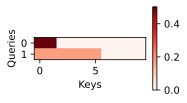

In [11]:
d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')

## 10.3.3 缩放点积注意力（Scaled Dot-Product Attention）

### 1. 工作原理

缩放点积注意力通过 Q 和 K 的点积衡量匹配程度，再除以 $\sqrt{d}$ 控制分数尺度，经过 Softmax 得到注意力权重，最后对 V 加权求和。

**缩放点积注意力公式：**

$$
\boxed{\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V}
$$

其中，$d$ 为 Query 和 Key 的共同特征维度，$QK^\top$ 用于一次性计算所有 Query-Key 组合的匹配分数。

### 2. 为什么要除以 $\sqrt{d}$？

**核心原因：随着特征维度 $d$ 增大，点积分数的方差可能增大，导致 Softmax 输出过度集中、梯度变小，不利于模型训练。**

假设 Q、K 都是 $d$ 维向量，所有元素相互独立，均值为 0、方差为 1：

$$
E(q_i)=E(k_i)=0,\quad Var(q_i)=Var(k_i)=1
$$

**第一步：推导点积中单项乘积的方差。**

Q 和 K 的点积为：

$$
QK^\top=\sum_{i=1}^{d}q_ik_i
$$

令 $X_i=q_ik_i$，由独立性可得：

$$
E(X_i)=E(q_i)E(k_i)=0
$$

根据方差公式：

$$
Var(X_i)=E(X_i^2)-[E(X_i)]^2
$$

又因为 $E(q_i^2)=E(k_i^2)=1$，所以：

$$
Var(X_i)=E(q_i^2k_i^2)=E(q_i^2)E(k_i^2)=\boxed{1}
$$

**第二步：推导整个点积的方差。**

由于各项 $X_i$ 相互独立，利用独立随机变量的方差可加性：

$$
\boxed{Var(QK^\top)=\sum_{i=1}^{d}Var(X_i)=d}
$$

即点积的方差随特征维度 $d$ 线性增大，其标准差为 $\sqrt d$。

**第三步：除以 $\sqrt d$，将方差缩放至 1。**

利用方差性质：

$$
Var(aX)=a^2Var(X)
$$

因此：

$$
\begin{aligned}
Var\left(\frac{QK^\top}{\sqrt d}\right)&=\left(\frac1{\sqrt d}\right)^2Var(QK^\top)\\
&=\frac1d\times d\\
&=\boxed{1}
\end{aligned}
$$

例如，当 $d=64$ 时，原始点积方差为 64、标准差为 8；除以 $\sqrt{64}=8$ 后，方差变为 1、标准差变为 1。

### 3. 核心总结

**缩放点积注意力通过矩阵乘法 $QK^\top$ 高效计算所有 Q-K 匹配分数，并利用 $\sqrt d$ 缩放，使分数的波动尺度不随特征维度增大而显著扩大，从而缓解 Softmax 饱和及梯度过小的问题。**

需要注意，方差等于 1 的推导建立在元素独立、零均值、单位方差的理想假设下，实际模型中的 Q、K 不一定严格满足这些条件。

In [13]:
class DotProductAttention(nn.Module):
    def __init__(self, dropout, **kwargs):
        super().__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)

    # queries的形状：(batch_size，查询的个数，d)
    # keys的形状：(batch_size，“键－值”对的个数，d)
    # values的形状：(batch_size，“键－值”对的个数，值的维度)
    # valid_lens的形状:(batch_size，)或者(batch_size，查询的个数)
    def forward(self, queries, keys, values, valid_lens=None):
        d = queries.shape[-1]
        scores = torch.bmm(queries, keys.transpose(1,2)) / math.sqrt(d)
        self.attention_weights = masked_softmax(scores, valid_lens)
        return torch.bmm(self.dropout(self.attention_weights), values) # 权重矩阵和value矩阵做运算，返回结果


缩放点积注意力通过 $QK^\top$ 一次性计算所有 Query-Key 组合的匹配分数，再除以 $\sqrt d$ 控制分数尺度。

$$
\boxed{S=\frac{QK^\top}{\sqrt d}}
$$

**第一步：构造 Q、K。**

假设一个 Batch 包含 2 个 Query、3 个 Key，每个向量都是二维的，因此 $d=2$。

$$
Q=\begin{bmatrix}1&2\\3&4\end{bmatrix},\quad K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}
$$

对应张量形状：

$$
Q:(1,2,2),\quad K:(1,3,2)
$$

**第二步：将 K 转置，计算所有 Q-K 点积。**

`keys.transpose(1, 2)` 交换 Key 张量的第 1、2 维，Batch 维度保持不变。

$$
K^\top=\begin{bmatrix}1&0&1\\0&1&1\end{bmatrix}
$$

执行 `torch.bmm(queries, keys.transpose(1, 2))`：

$$
QK^\top=\begin{bmatrix}1&2\\3&4\end{bmatrix}\begin{bmatrix}1&0&1\\0&1&1\end{bmatrix}
$$

第一个 Query 与三个 Key 分别计算点积：

$$
\begin{aligned}
q_1\cdot k_1&=1\times1+2\times0=1\\
q_1\cdot k_2&=1\times0+2\times1=2\\
q_1\cdot k_3&=1\times1+2\times1=3
\end{aligned}
$$

第二个 Query 同理：

$$
\begin{aligned}
q_2\cdot k_1&=3\times1+4\times0=3\\
q_2\cdot k_2&=3\times0+4\times1=4\\
q_2\cdot k_3&=3\times1+4\times1=7
\end{aligned}
$$

因此：

$$
\boxed{QK^\top=\begin{bmatrix}1&2&3\\3&4&7\end{bmatrix}}
$$

**第三步：除以 $\sqrt d$，得到最终注意力分数。**

由于 $d=2$，将所有点积分数除以 $\sqrt2\approx1.414$：

$$
\boxed{S=\frac{QK^\top}{\sqrt2}\approx\begin{bmatrix}0.707&1.414&2.121\\2.121&2.828&4.950\end{bmatrix}}
$$

最终 `scores.shape=(1,2,3)`，表示 1 个 Batch、2 个 Query，每个 Query 对应 3 个 Key 的注意力分数。

### 核心总结

**矩阵乘法 $QK^\top$ 能直接实现所有 Q-K 的两两点积，无需像加性注意力那样通过 `unsqueeze` 和广播构造四维 Feature 张量。**

一般形状变化：

$$
\boxed{(B,n,d)\times(B,d,m)\rightarrow(B,n,m)}
$$

其中 $B$ 为 Batch 大小，$n$ 为 Query 数量，$m$ 为 Key 数量，$d$ 为 Q、K 的特征维度。

注意：**这一步只计算注意力分数，后续还需要经过 Masked Softmax 得到注意力权重，再与 Value 加权求和。**

In [ ]:
queries = torch.normal(0, 1, (2, 1, 2))
# q.shape:(2,1,2), k.shape:(2,10,2)
attention = DotProductAttention(dropout=0.5)
attention.eval()
attention(queries, keys, values, valid_lens)

tensor([[[ 2.0000,  3.0000,  4.0000,  5.0000]],

        [[10.0000, 11.0000, 12.0000, 13.0000]]])

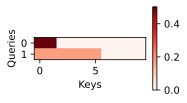

In [15]:
d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')